In [1]:
#Cell 1: Load Data from SupaBase

import os
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from supabase import create_client

load_dotenv(find_dotenv(usecwd=True))
client = create_client(os.getenv("SUPABASE_URL"), os.getenv("SUPABASE_ANON_KEY"))


def load_table(name, page=1000):
    rows, start = [], 0
    while True:
        chunk = client.table(name).select("*").range(start, start + page - 1).execute().data
        rows.extend(chunk)
        if len(chunk) < page:
            break
        start += page
    return pd.DataFrame(rows)


repos = load_table("repos")
events = load_table("events")
commits = load_table("commits")
prs = load_table("pull_requests")
issues = load_table("issues")

for name, df in [("repos", repos), ("events", events), ("commits", commits),
                 ("prs", prs), ("issues", issues)]:
    print(name, df.shape)

repos (24, 8)
events (6926, 6)
commits (12594, 5)
prs (16220, 10)
issues (7205, 10)


In [ ]:
commits.head(1)

In [ ]:
prs.head()
commits.info()

In [ ]:
repos[["full_name", "language", "stars"]]

In [3]:
# Cell 2: Clean data (convert dates, add repo name)

for df, col in [(events, "created_at"), (commits, "committed_at"),
                (prs, "created_at"), (issues, "created_at")]:
    df[col] = pd.to_datetime(df[col], utc=True)

names = repos.set_index("id")["full_name"]
for df in (events, commits, prs, issues):
    df["repo"] = df["repo_id"].map(names)

In [4]:
# Short label = repo name only

for df in (events, commits, prs, issues):
    df["label"] = df["repo"].str.split("/").str[1]

In [20]:
# Keep the last 60 days only, so time-based charts are fair
cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=60)
commits = commits[commits["committed_at"] >= cutoff].copy()

In [21]:
# Cell 3: Check data caps per repo

cap = commits.groupby("label")["committed_at"].agg(["count", "min", "max"])
cap.sort_values("count", ascending=False).head(10)

,count,min,max
label,,,
kubernetes,2133,2026-09-08 12:40:30+00:00,2026-11-06 22:29:46+00:00
nocodb,1496,2026-09-08 12:35:05+00:00,2026-11-04 08:54:16+00:00
spring-boot,1300,2026-09-08 12:54:37+00:00,2026-11-06 16:30:19+00:00
next.js,1141,2026-09-08 13:38:33+00:00,2026-11-06 21:41:20+00:00
motion,1120,2026-09-09 03:11:54+00:00,2026-11-06 14:05:42+00:00
fiber,955,2026-09-08 12:47:57+00:00,2026-11-06 13:40:41+00:00
react-native,885,2026-09-08 13:07:25+00:00,2026-11-06 19:47:12+00:00
moby,797,2026-09-08 15:14:14+00:00,2026-11-06 01:17:22+00:00
strapi,569,2026-09-08 14:13:49+00:00,2026-11-06 17:22:05+00:00


In [7]:
# Cell 4: Add category column from repos.json

root = Path.cwd()

while not (root / "data" / "selected_repos.json").exists():
    root = root.parent
cats = json.loads((root / "data" / "selected_repos.json").read_text(encoding="utf-8"))
cat_map = {name: cat for cat, names_ in cats.items() for name in names_}

for df in (events, commits, prs, issues):
    df["category"] = df["repo"].map(cat_map).fillna("other")

commits["category"].value_counts()

category
deployment    3874
backend       3488
database      2728
frontend      2504
Name: count, dtype: int64

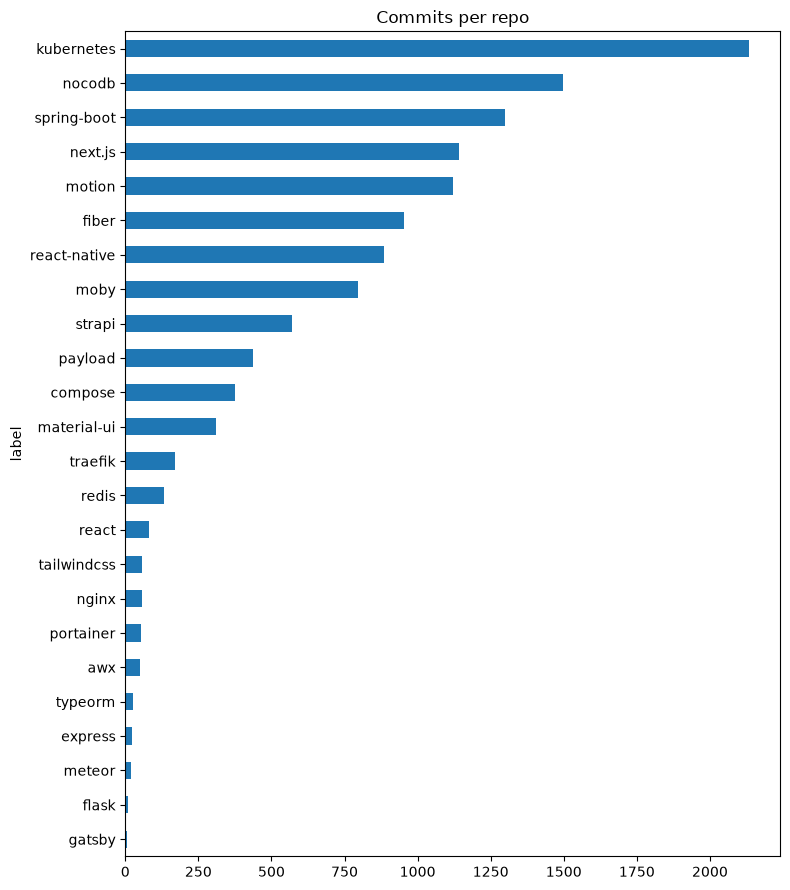

In [22]:
# Cell 5: Commits per repo

commits["label"].value_counts().sort_values().plot(
    kind="barh", figsize=(8, 9), title="Commits per repo"
)
plt.tight_layout()
plt.show()

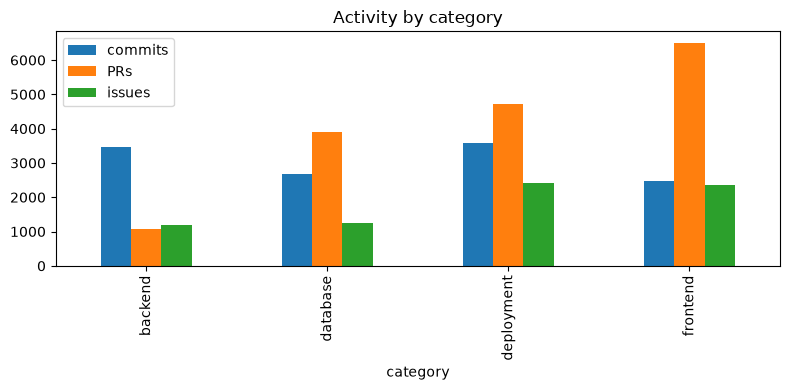

In [23]:
# Cell 6: Activity by category

summary = pd.DataFrame({
    "commits": commits["category"].value_counts(),
    "PRs": prs["category"].value_counts(),
    "issues": issues["category"].value_counts(),
}).fillna(0).astype(int)

summary.plot(kind="bar", figsize=(8, 4), title="Activity by category")
plt.tight_layout()
plt.show()

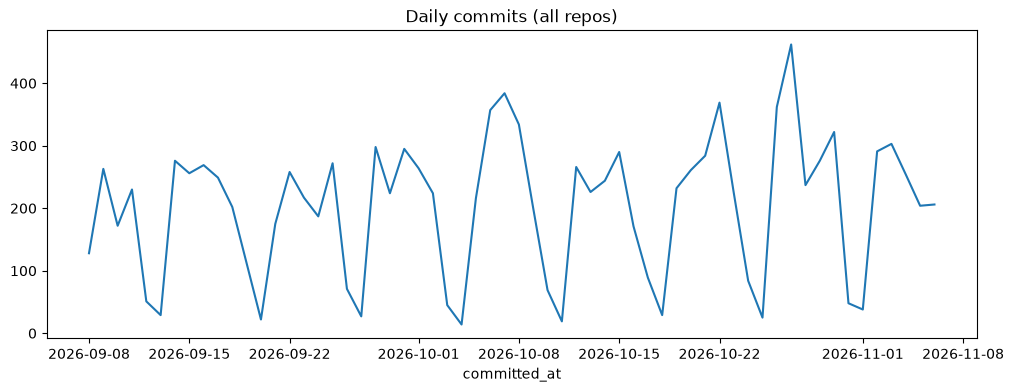

In [24]:
# Cell 7: Daily commit trend

daily = commits.groupby(commits["committed_at"].dt.date).size()
daily.plot(figsize=(12, 4), title="Daily commits (all repos)")
plt.show()

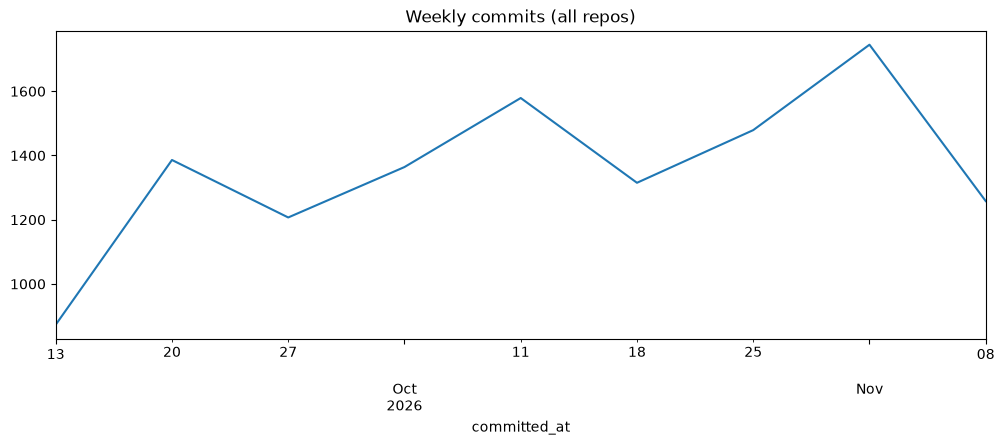

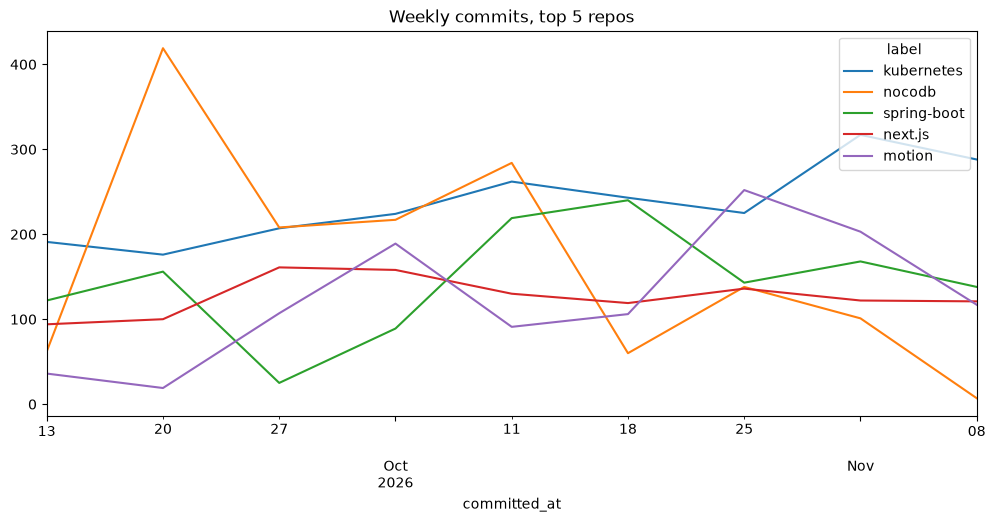

In [25]:
# Cell 8: Weekly commit trend

weekly = commits.groupby(
    [pd.Grouper(key="committed_at", freq="W"), "label"]
).size().unstack(fill_value=0)

weekly.sum(axis=1).plot(figsize=(12, 4), title="Weekly commits (all repos)")
plt.show()

weekly[weekly.sum().nlargest(5).index].plot(
    figsize=(12, 5), title="Weekly commits, top 5 repos"
)
plt.show()

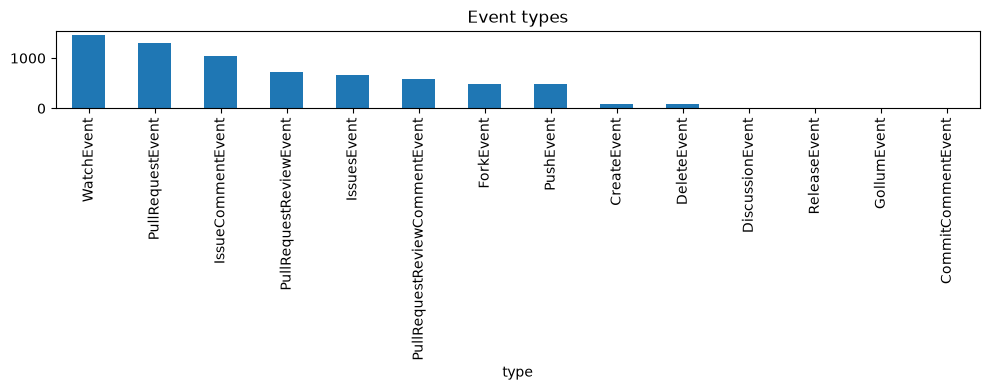

In [26]:
# Cell 9: Event type distribution

events["type"].value_counts().plot(kind="bar", figsize=(10, 4), title="Event types")
plt.tight_layout()
plt.show()

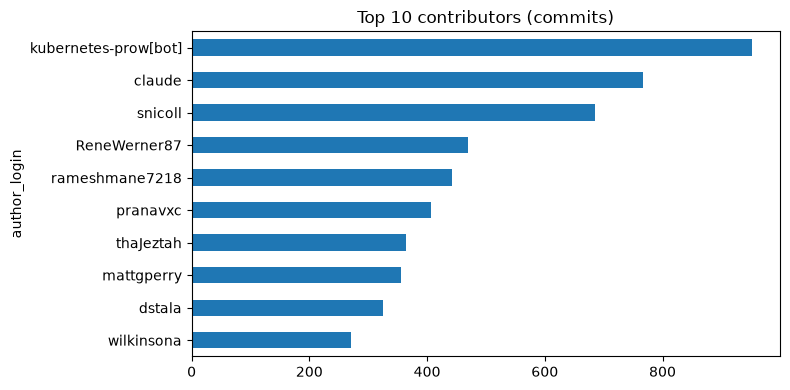

commits without login: 76


In [27]:
# Cell 10: Top 10 contributors

commits["author_login"].dropna().value_counts().head(10).sort_values().plot(
    kind="barh", figsize=(8, 4), title="Top 10 contributors (commits)"
)
plt.tight_layout()
plt.show()
print("commits without login:", commits["author_login"].isna().sum())

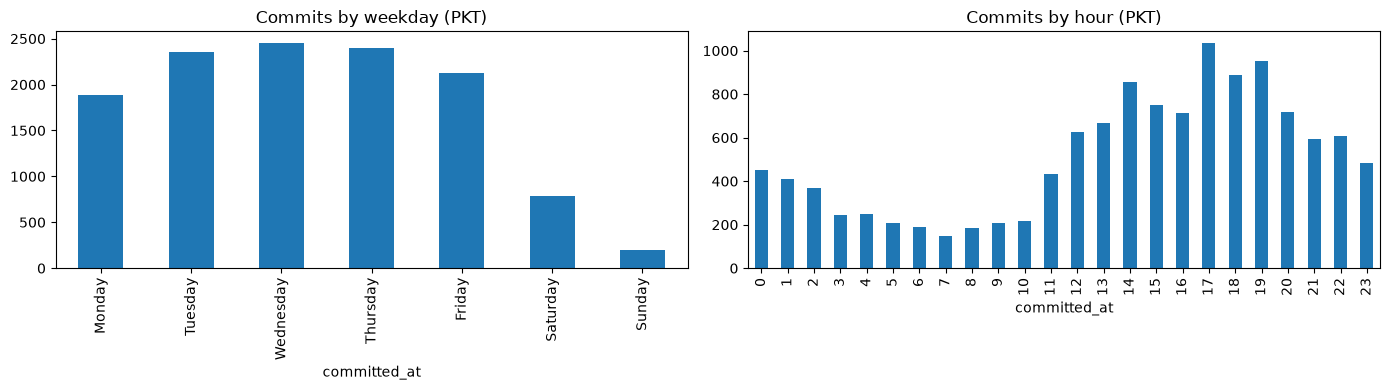

In [28]:
# Cell 11: Weekday and hour-of-day patterns (Pakistan time)

local = commits["committed_at"].dt.tz_convert("Asia/Karachi")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
local.dt.day_name().value_counts().reindex(order).plot(
    kind="bar", ax=axes[0], title="Commits by weekday (PKT)"
)
local.dt.hour.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Commits by hour (PKT)"
)
plt.tight_layout()
plt.show()

In [29]:
# Cell 12: Pull request state and time to merge

print(prs["state"].value_counts())

merged = prs.dropna(subset=["merged_at"]).copy()
merged["merged_at"] = pd.to_datetime(merged["merged_at"], utc=True)
merged["hours_to_merge"] = (
    (merged["merged_at"] - merged["created_at"]).dt.total_seconds() / 3600
)
print(merged["hours_to_merge"].describe())

state
closed    10630
open       5590
Name: count, dtype: int64
count     6712.000000
mean       270.614756
std        884.665264
min          0.002778
25%          4.198403
50%         31.509722
75%        163.611875
max      24880.895000
Name: hours_to_merge, dtype: float64


In [17]:
# Cell 13: Missing value check

for name, df in [("events", events), ("commits", commits), ("prs", prs), ("issues", issues)]:
    print(f"\n{name}")
    print(df.isna().sum()[lambda s: s > 0])


events
action    654
dtype: int64

commits
author_login    77
dtype: int64

prs
closed_at    5590
merged_at    9508
dtype: int64

issues
closed_at    3188
dtype: int64


count    1028.000000
mean       12.250973
std        16.691812
min         1.000000
25%         2.000000
50%         5.000000
75%        17.000000
max       150.000000
dtype: float64
repo                         committed_at
gofiber/fiber                2026-10-27      150
motiondivision/motion        2026-10-22      146
spring-projects/spring-boot  2026-10-06      119
nocodb/nocodb                2026-09-14      102
spring-projects/spring-boot  2026-10-12       91
dtype: int64


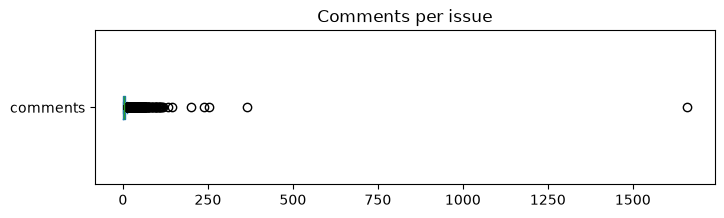

In [18]:
# Cell 14: Outlier check

per_day = commits.groupby(["repo", commits["committed_at"].dt.date]).size()
print(per_day.describe())
print(per_day.nlargest(5))

issues["comments"].plot(kind="box", vert=False, figsize=(8, 2), title="Comments per issue")
plt.show()